In [2]:
import sys
import platform

print("¡Bienvenido al proyecto de IA!")
print("Proyecto: Asistente de Evaluación Regulatoria")
print("Versión de Python:", sys.version.split()[0])
print("Sistema operativo:", platform.system())


¡Bienvenido al proyecto de IA!
Proyecto: Asistente de Evaluación Regulatoria
Versión de Python: 3.12.15
Sistema operativo: Linux


In [1]:

%pip install -q scikit-learn pandas joblib


Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd

datos = {
    "proyecto": [
        "Apertura de cuenta mediante reconocimiento facial",
        "Aplicación que comparte información de clientes con terceros",
        "Chatbot que responde preguntas sobre productos bancarios",
        "Plataforma de transferencias electrónicas",
        "Aplicación para consultar saldos y movimientos",
        "Sistema de inteligencia artificial para evaluar créditos"
    ],
    "riesgo": [
        "Identidad digital",
        "Protección de datos",
        "Información al cliente",
        "Seguridad transaccional",
        "Seguridad de acceso",
        "Decisiones automatizadas"
    ]
}

df = pd.DataFrame(datos)

display(df)


,proyecto,riesgo
0,Apertura de cuenta mediante reconocimiento facial,Identidad digital
1,Aplicación que comparte información de cliente...,Protección de datos
2,Chatbot que responde preguntas sobre productos...,Información al cliente
3,Plataforma de transferencias electrónicas,Seguridad transaccional
4,Aplicación para consultar saldos y movimientos,Seguridad de acceso
5,Sistema de inteligencia artificial para evalua...,Decisiones automatizadas


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

modelo = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clasificador", MultinomialNB())
])

modelo.fit(df["proyecto"], df["riesgo"])

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [4]:
nuevo_proyecto = [
    "Aplicación bancaria que permite realizar transferencias de dinero entre clientes"
]

prediccion = modelo.predict(nuevo_proyecto)

print("Proyecto:", nuevo_proyecto[0])
print("Riesgo regulatorio identificado:", prediccion[0])

Proyecto: Aplicación bancaria que permite realizar transferencias de dinero entre clientes
Riesgo regulatorio identificado: Protección de datos


In [5]:
probabilidades = modelo.predict_proba(nuevo_proyecto)[0]
categorias = modelo.classes_

resultados = pd.DataFrame({
    "Riesgo": categorias,
    "Probabilidad estimada": probabilidades
})

resultados = resultados.sort_values(
    by="Probabilidad estimada",
    ascending=False
)

display(resultados)

,Riesgo,Probabilidad estimada
3,Protección de datos,0.211405
5,Seguridad transaccional,0.191243
4,Seguridad de acceso,0.158261
2,Información al cliente,0.150365
1,Identidad digital,0.145551
0,Decisiones automatizadas,0.143175


In [6]:
nuevos_datos = {
    "proyecto": [
        "Transferencias electrónicas entre cuentas bancarias",
        "Sistema de pagos digitales mediante aplicación móvil",
        "Plataforma para enviar dinero a otros bancos",
        "Aplicación que solicita consentimiento para compartir datos personales",
        "Sistema de almacenamiento de información personal de clientes",
        "Plataforma que comparte datos de clientes con terceros",
        "Sistema de autenticación mediante reconocimiento facial",
        "Apertura de cuentas mediante identificación biométrica",
        "Verificación digital de identidad de clientes",
        "Chatbot que informa sobre comisiones bancarias",
        "Asistente virtual que explica características de productos financieros",
        "Sistema que proporciona información sobre condiciones contractuales",
        "Aplicación de acceso mediante contraseña y token",
        "Sistema de autenticación de usuarios en banca móvil",
        "Plataforma de control de acceso a cuentas bancarias",
        "Modelo de inteligencia artificial para aprobar créditos",
        "Sistema automatizado de evaluación de solicitudes de préstamo",
        "Algoritmo que decide sobre el otorgamiento de financiamiento"
    ],
    "riesgo": [
        "Seguridad transaccional",
        "Seguridad transaccional",
        "Seguridad transaccional",
        "Protección de datos",
        "Protección de datos",
        "Protección de datos",
        "Identidad digital",
        "Identidad digital",
        "Identidad digital",
        "Información al cliente",
        "Información al cliente",
        "Información al cliente",
        "Seguridad de acceso",
        "Seguridad de acceso",
        "Seguridad de acceso",
        "Decisiones automatizadas",
        "Decisiones automatizadas",
        "Decisiones automatizadas"
    ]
}

df_nuevos = pd.DataFrame(nuevos_datos)

df_ampliado = pd.concat(
    [df, df_nuevos],
    ignore_index=True
)

print("Total de proyectos:", len(df_ampliado))
display(df_ampliado.groupby("riesgo").size())

Total de proyectos: 24


riesgo
Decisiones automatizadas    4
Identidad digital           4
Información al cliente      4
Protección de datos         4
Seguridad de acceso         4
Seguridad transaccional     4
dtype: int64

In [7]:
modelo_v2 = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clasificador", MultinomialNB())
])

modelo_v2.fit(
    df_ampliado["proyecto"],
    df_ampliado["riesgo"]
)

print("Modelo versión 2 entrenado correctamente")

prediccion_v2 = modelo_v2.predict(nuevo_proyecto)

print("Proyecto:", nuevo_proyecto[0])
print("Predicción original:", prediccion[0])
print("Predicción versión 2:", prediccion_v2[0])

Modelo versión 2 entrenado correctamente
Proyecto: Aplicación bancaria que permite realizar transferencias de dinero entre clientes
Predicción original: Protección de datos
Predicción versión 2: Seguridad transaccional


In [8]:
pruebas = [
    "Banco que permite enviar pagos a otras instituciones",
    "Aplicación que recopila datos personales de usuarios",
    "Sistema que verifica la identidad mediante huella digital",
    "Asistente que explica las comisiones de una tarjeta",
    "Plataforma que permite iniciar sesión con contraseña",
    "Algoritmo que determina si un cliente recibe un préstamo"
]

resultados_pruebas = modelo_v2.predict(pruebas)

df_pruebas = pd.DataFrame({
    "Proyecto evaluado": pruebas,
    "Riesgo identificado": resultados_pruebas
})

display(df_pruebas)

,Proyecto evaluado,Riesgo identificado
0,Banco que permite enviar pagos a otras institu...,Seguridad transaccional
1,Aplicación que recopila datos personales de us...,Protección de datos
2,Sistema que verifica la identidad mediante hue...,Identidad digital
3,Asistente que explica las comisiones de una ta...,Información al cliente
4,Plataforma que permite iniciar sesión con cont...,Protección de datos
5,Algoritmo que determina si un cliente recibe u...,Decisiones automatizadas


In [9]:
from sklearn.metrics import accuracy_score, classification_report

esperados = [
    "Seguridad transaccional",
    "Protección de datos",
    "Identidad digital",
    "Información al cliente",
    "Seguridad de acceso",
    "Decisiones automatizadas"
]

precision = accuracy_score(esperados, resultados_pruebas)

print("Exactitud en pruebas:", round(precision * 100, 2), "%")

print("\nReporte de clasificación:")
print(classification_report(
    esperados,
    resultados_pruebas,
    zero_division=0
))

Exactitud en pruebas: 83.33 %

Reporte de clasificación:
                          precision    recall  f1-score   support

Decisiones automatizadas       1.00      1.00      1.00         1
       Identidad digital       1.00      1.00      1.00         1
  Información al cliente       1.00      1.00      1.00         1
     Protección de datos       0.50      1.00      0.67         1
     Seguridad de acceso       0.00      0.00      0.00         1
 Seguridad transaccional       1.00      1.00      1.00         1

                accuracy                           0.83         6
               macro avg       0.75      0.83      0.78         6
            weighted avg       0.75      0.83      0.78         6



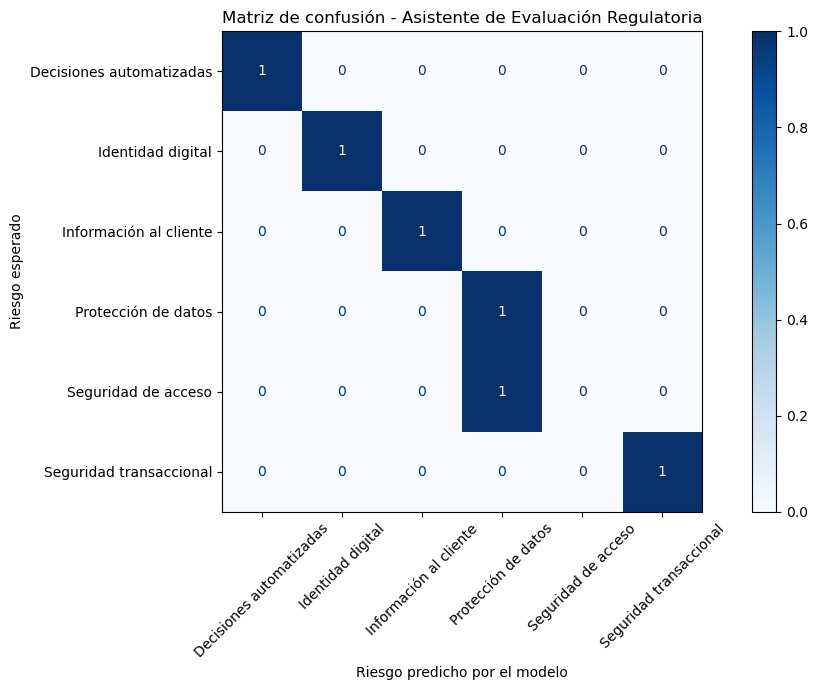

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(11, 7))

ConfusionMatrixDisplay.from_predictions(
    esperados,
    resultados_pruebas,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Matriz de confusión - Asistente de Evaluación Regulatoria")
plt.xlabel("Riesgo predicho por el modelo")
plt.ylabel("Riesgo esperado")
plt.tight_layout()
plt.show()

In [11]:
fig.savefig(
    "matriz_confusion_regulatoria.png",
    dpi=300,
    bbox_inches="tight"
)

print("Gráfica guardada correctamente")

Gráfica guardada correctamente


In [12]:
import joblib

joblib.dump(
    modelo_v2,
    "modelo_asistente_regulatorio_v2.joblib"
)

print("Modelo versión 2 guardado correctamente")

Modelo versión 2 guardado correctamente
